In [ ]:
# Install the packages used for posterior predictive diagnostics and mapping.
!pip install geopandas -q
!pip install arviz==0.23.0 -q
!pip install pymc -q
!pip install nutpie -q
!pip install numpyro -q
!pip install matplotlib_scalebar -q
!apt-get install -y ttf-mscorefonts-installer -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 72.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 73.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 70.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.7/363.7 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 68.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.8/394.8 kB 17.9 MB/s eta 0:00:00
Reading package lists...
Building dependency tree...
Reading state information...
The following additional packages will be installed:
  cabextract distro-info libmspack0t64 python3-chardet python3-debconf
  python3-debian python3-distro-info python3-distupgrade
  python3-update-manager python3-yaml ubuntu-pro-client ubuntu-pro-client-l10n
  ubuntu-release-upgrader-core update-manager-core update-notifier-common
  xfonts-encodings xfonts-utils zstd


In [ ]:
# Import packages for inference diagnostics, geospatial statistics, and visualization.
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from glob import glob
import libpysal.weights as lw
from libpysal.weights import Queen

import os
import shutil
import warnings
import arviz as az
import pymc as pm
import pytensor.tensor as pt

import networkx as nx
import nutpie

from sklearn.preprocessing import StandardScaler

from matplotlib_scalebar.scalebar import ScaleBar

from scipy import sparse
from scipy.linalg import solve
from scipy.sparse.linalg import spsolve
warnings.filterwarnings("ignore")

/usr/local/lib/python3.13/dist-packages/arviz/__init__.py:39: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


In [ ]:
shutil.rmtree(mpl.get_cachedir(), ignore_errors=True)
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman'] + plt.rcParams['font.serif']
plt.rcParams['mathtext.fontset'] = 'stix'

In [ ]:
# Load the same analysis geography used to construct the fitted spatial model.
df_gpkg = gpd.read_file("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/解析用結合データ②.geojson")

In [ ]:
# Summarize where an observed summary statistic lies within its posterior predictive distribution.
def summarize_ppc(obs, rep, name):
    q = np.quantile(rep, [0.025, 0.5, 0.975])

    # Compute the percentile rank of the observed statistic
    # within the posterior predictive distribution.
    percentile = np.mean(rep <= obs)

    print(f"\n{name}")
    print(f"Observed            : {obs:.3f}")
    print(f"Posterior median    : {q[1]:.3f}")
    print(f"Posterior 95% PI    : [{q[0]:.3f}, {q[2]:.3f}]")
    print(f"Observed percentile : {percentile:.3f}")


Poisson BYM2 model: posterior predictive checks

In [ ]:
# Load saved Poisson BYM2 posterior samples and generated observations.
idata_p = az.from_netcdf("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/inference_data_p.nc")

In [ ]:
# Inspect the groups and observation variables available in the saved inference data.
print(idata_p)
print("\nGroups:")
print(idata_p.groups())

# Inspect variable names stored in the posterior predictive group.
if hasattr(idata_p, "posterior_predictive"):
    print("\nposterior_predictive variables:")
    print(list(idata_p.posterior_predictive.data_vars))

# Inspect variable names stored in the observed data group.
if hasattr(idata_p, "observed_data"):
    print("\nobserved_data variables:")
    print(list(idata_p.observed_data.data_vars))

Inference data with groups:
	> posterior
	> posterior_predictive
	> sample_stats
	> observed_data
	> constant_data

Groups:
['posterior', 'posterior_predictive', 'sample_stats', 'observed_data', 'constant_data']

posterior_predictive variables:
['y_i']

observed_data variables:
['y_i']


In [ ]:
# Inspect the dimensions of posterior predictive counts.
print(idata_p.posterior_predictive["y_i"])

<xarray.DataArray 'y_i' (chain: 4, draw: 3000, area: 227)> Size: 22MB
[2724000 values with dtype=int64]
Coordinates:
  * chain    (chain) int64 32B 0 1 2 3
  * draw     (draw) int64 24kB 0 1 2 3 4 5 6 ... 2994 2995 2996 2997 2998 2999
  * area     (area) int64 2kB 0 1 2 3 4 5 6 7 ... 220 221 222 223 224 225 226


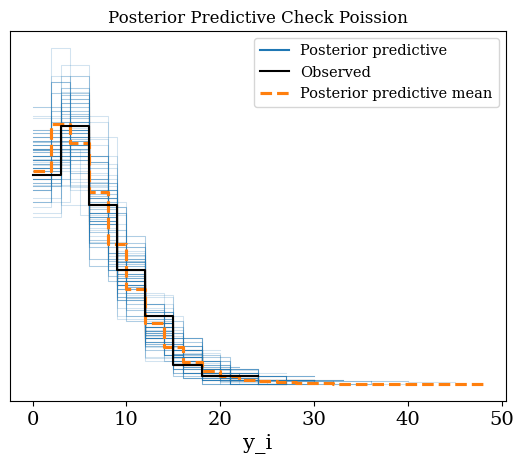

In [ ]:
# Compare observed and simulated death-count distributions using kernel density estimates.
az.plot_ppc(idata_p, var_names=["y_i"], kind="kde", num_pp_samples=100, random_seed=123)
plt.title("Posterior Predictive Check Poission")
plt.show()

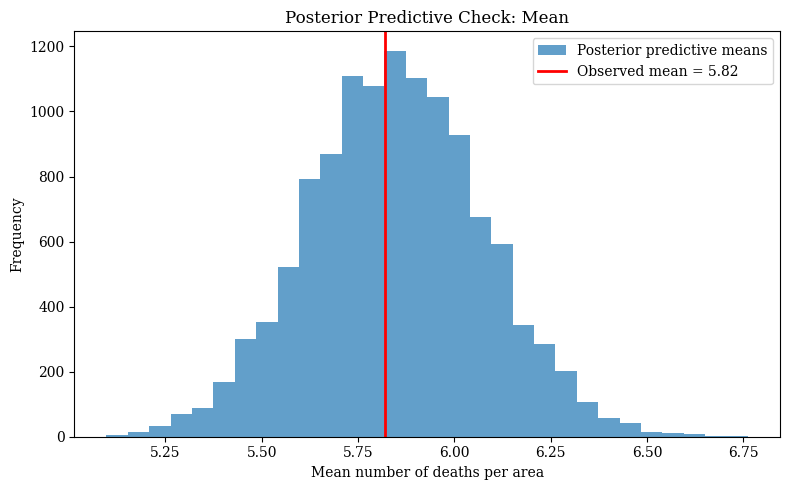

In [ ]:
# Assess whether the model reproduces the mean count across areas.
ppc_mean_p = (idata_p.posterior_predictive["y_i"].mean(dim="area"))

# Calculate the observed mean count across all areas.
obs_mean_p = (idata_p.observed_data["y_i"].mean(dim="area"))

# Flatten the chain and draw dimensions into posterior predictive samples.
ppc_mean_values_p = ppc_mean_p.values.flatten()

plt.figure(figsize=(8, 5))
plt.hist(ppc_mean_values_p, bins=30, alpha=0.7, label="Posterior predictive means")

plt.axvline(float(obs_mean_p.values), color="red", linewidth=2, label=f"Observed mean = {float(obs_mean_p.values):.2f}")

plt.xlabel("Mean number of deaths per area")
plt.ylabel("Frequency")
plt.title("Posterior Predictive Check: Mean")
plt.legend()
plt.tight_layout()
plt.show()

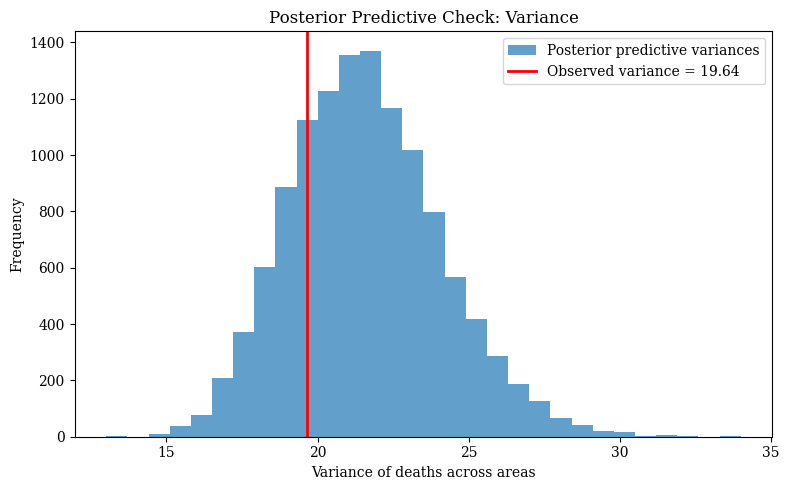

In [ ]:
# Assess whether the model reproduces spatial variation in area-level counts.
# Calculate the observed variance across all areas.
obs_var_p = (idata_p.observed_data["y_i"].var(dim="area", ddof=1))

# Calculate the cross-area variance for each posterior predictive draw.
ppc_var_p = (idata_p.posterior_predictive["y_i"].var(dim="area", ddof=1))

ppc_var_values_p = ppc_var_p.values.flatten()

plt.figure(figsize=(8, 5))
plt.hist(ppc_var_values_p, bins=30, alpha=0.7, label="Posterior predictive variances")

plt.axvline(float(obs_var_p.values), color="red", linewidth=2, label=f"Observed variance = {float(obs_var_p.values):.2f}")

plt.xlabel("Variance of deaths across areas")
plt.ylabel("Frequency")
plt.title("Posterior Predictive Check: Variance")
plt.legend()
plt.tight_layout()
plt.show()

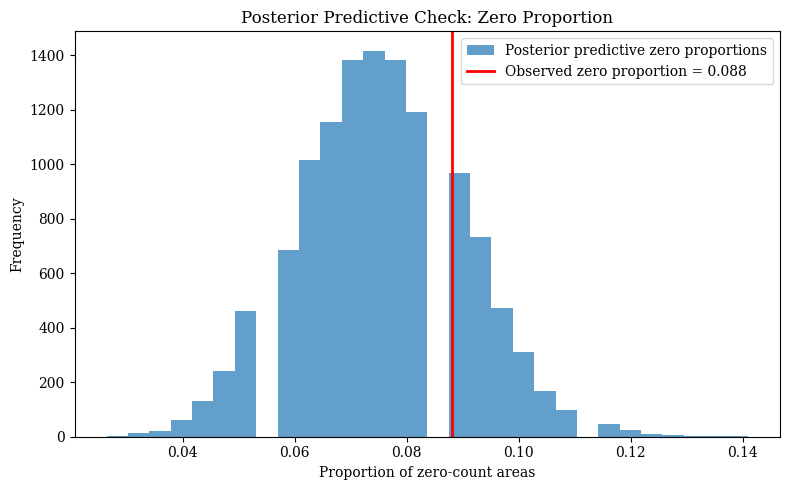

In [ ]:
# Assess whether the model reproduces the fraction of zero-count areas.
# Compare the observed and replicated proportions of zero-count areas.

obs_zero_p = (idata_p.observed_data["y_i"] == 0).mean(dim="area")

ppc_zero_p = (idata_p.posterior_predictive["y_i"] == 0).mean(dim="area")

ppc_zero_values_p = ppc_zero_p.values.flatten()

plt.figure(figsize=(8, 5))

plt.hist(ppc_zero_values_p, bins=30, alpha=0.7, label="Posterior predictive zero proportions")
plt.axvline(float(obs_zero_p.values), color="red", linewidth=2, label=f"Observed zero proportion = {float(obs_zero_p.values):.3f}")

plt.xlabel("Proportion of zero-count areas")
plt.ylabel("Frequency")
plt.title("Posterior Predictive Check: Zero Proportion")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Summarize posterior predictive checks for mean, variance, and zero fraction.
# Posterior predictive statistics
ppc_mean_values_p = (idata_p.posterior_predictive["y_i"].mean(dim="area").values.flatten())

ppc_var_values_p = (idata_p.posterior_predictive["y_i"].var(dim="area", ddof=1).values.flatten())

ppc_zero_values_p = ((idata_p.posterior_predictive["y_i"] == 0).mean(dim="area").values.flatten())

# Observed statistics
y_obs_p = idata_p.observed_data["y_i"]

obs_mean_p = float(y_obs_p.mean(dim="area").values)
obs_var_p = float(y_obs_p.var(dim="area", ddof=1).values)
obs_zero_p = float((y_obs_p == 0).mean(dim="area").values)

summarize_ppc(obs_mean_p, ppc_mean_values_p, "Mean")
summarize_ppc(obs_var_p, ppc_var_values_p, "Variance")
summarize_ppc(obs_zero_p, ppc_zero_values_p, "Zero proportion")


Mean
Observed            : 5.819
Posterior median    : 5.850
Posterior 95% PI    : [5.405, 6.300]
Observed percentile : 0.457

Variance
Observed            : 19.635
Posterior median    : 21.455
Posterior 95% PI    : [17.144, 26.953]
Observed percentile : 0.223

Zero proportion
Observed            : 0.088
Posterior median    : 0.075
Posterior 95% PI    : [0.048, 0.106]
Observed percentile : 0.844


In [ ]:
# Begin the residual spatial autocorrelation diagnostic.
# Evaluate residual spatial autocorrelation with Moran's I.

from libpysal.weights import W
from esda.moran import Moran

# 1. Extract the observed death counts.
y_obs_p = (idata_p.observed_data["y_i"].values.squeeze())
print("Number of areas:", len(y_obs_p))



Number of areas: 227


In [ ]:
# Obtain posterior mean fitted counts for each area.
# 2. Obtain each area's fitted mean from the posterior distribution.
mu_hat_p = (idata_p.posterior["mu"].mean(dim=("chain", "draw")).values)

print("mu_hat shape:", mu_hat_p.shape)

mu_hat shape: (227,)


In [ ]:
# Compute Pearson residuals for the Poisson mean-variance relationship.
# Compute Pearson residuals using the posterior mean fitted counts.

pearson_resid_p = (y_obs_p - mu_hat_p) / np.sqrt(mu_hat_p)

print("Residual mean:", np.mean(pearson_resid_p))
print("Residual SD:", np.std(pearson_resid_p, ddof=1))

Residual mean: -0.062431861673174646
Residual SD: 0.8199414410706348


In [ ]:
# Rebuild the queen-neighbor matrix for spatial diagnostics.
# Reconstruct the original queen-contiguity adjacency matrix.
df_gpkg = gpd.read_file("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/解析用結合データ②.geojson")
w_queen = Queen.from_dataframe(df_gpkg, ids=df_gpkg["id"].to_list())
w_queen_np = w_queen.full()[0]

In [ ]:
# Build the PySAL W object in the same area order as the model.
# Convert the BYM2 adjacency matrix into a PySAL weights object.
W_matrix = np.asarray(w_queen_np)

n_area = W_matrix.shape[0]

neighbors = {}
weights = {}

for i in range(n_area):
    nb = np.where(W_matrix[i] != 0)[0].tolist()
    neighbors[i] = nb
    weights[i] = [1.0] * len(nb)

w_pysal = W(neighbors,weights)

# Row-standardize spatial weights for Moran's I.
w_pysal.transform = "r"

print(w_pysal)
print("Number of connected components:", w_pysal.n_components)

Number of connected components: 1


In [ ]:
# Test for remaining spatial autocorrelation in Pearson residuals.
# Calculate global Moran's I for the Pearson residuals.

moran_resid = Moran(pearson_resid_p, w_pysal,permutations=9999)

print("\nResidual spatial autocorrelation")
print("--------------------------------")
print(f"Moran's I       : {moran_resid.I:.4f}")
print(f"Expected I      : {moran_resid.EI:.4f}")
print(f"Permutation p   : {moran_resid.p_sim:.4f}")
print(f"z-score         : {moran_resid.z_sim:.3f}")


Residual spatial autocorrelation
--------------------------------
Moran's I       : -0.0742
Expected I      : -0.0044
Permutation p   : 0.0357
z-score         : -1.758


In [ ]:
# Quantify global spatial autocorrelation in observed counts.
# Calculate Moran's I for the observed area-level death counts.

y_obs = idata_p.observed_data["y_i"].values.squeeze()

# Global Moran's I
moran_y = Moran(y_obs, w_pysal, permutations=9999)

print("Observed outcome spatial autocorrelation")
print("----------------------------------------")
print(f"Moran's I       : {moran_y.I:.4f}")
print(f"Expected I      : {moran_y.EI:.4f}")
print(f"Permutation p   : {moran_y.p_sim:.4f}")
print(f"z-score         : {moran_y.z_sim:.3f}")

Observed outcome spatial autocorrelation
----------------------------------------
Moran's I       : 0.2965
Expected I      : -0.0044
Permutation p   : 0.0001
z-score         : 7.636


In [ ]:
# Assess whether the fitted model reproduces global spatial autocorrelation.
# Compare the observed Moran's I against the posterior predictive distribution.

y_obs = idata.observed_data["y_i"].values.squeeze()
y_rep = (idata_p.posterior_predictive["y_i"].stack(sample=("chain", "draw")).transpose("sample", "area").values)

moran_obs = Moran(y_obs,w_pysal, permutations=9999)

I_obs = moran_obs.I

I_rep = np.empty(y_rep.shape[0])

for s in range(y_rep.shape[0]):
    # Only Moran's I statistics are required for each posterior predictive replicate;
    # A permutation test is unnecessary for each replicated dataset.
    moran_rep = Moran(y_rep[s, :], w_pysal, permutations=0)
    I_rep[s] = moran_rep.I

print("Number of PPC samples:", len(I_rep))

print("Posterior predictive Moran's I median:",np.median(I_rep))

print("Posterior predictive 95% interval:", np.quantile(I_rep, [0.025, 0.975]))

# 4. Measure the percentile of observed Moran's I in replicated values.
# ============================================================

I_percentile = np.mean(I_rep <= I_obs)

q025, q50, q975 = np.quantile(I_rep, [0.025, 0.50, 0.975])

print("\nSpatial posterior predictive check")
print("----------------------------------")
print(f"Observed Moran's I       : {I_obs:.4f}")
print(f"PP Moran's I median      : {q50:.4f}")
print(f"PP Moran's I 95% PI      : [{q025:.4f}, {q975:.4f}]")
print(f"Observed percentile      : {I_percentile:.3f}")

Number of PPC samples: 12000
Posterior predictive Moran's I median: 0.2870137942789706
Posterior predictive 95% interval: [0.20371353 0.370516  ]

Spatial posterior predictive check
----------------------------------
Observed Moran's I       : 0.2965
PP Moran's I median      : 0.2870
PP Moran's I 95% PI      : [0.2037, 0.3705]
Observed percentile      : 0.587


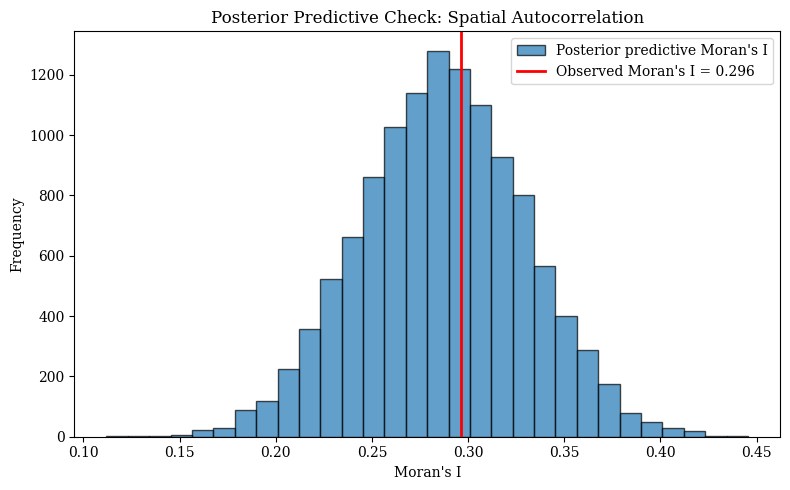

In [ ]:
# Visualize the posterior predictive Moran's I distribution and observed statistic.
plt.figure(figsize=(8, 5))

plt.hist(I_rep, bins=30, alpha=0.7, edgecolor="black", label="Posterior predictive Moran's I")

plt.axvline(I_obs, color="red", linewidth=2, label=f"Observed Moran's I = {I_obs:.3f}")

plt.xlabel("Moran's I")
plt.ylabel("Frequency")
plt.title("Posterior Predictive Check: Spatial Autocorrelation")
plt.legend()

plt.tight_layout()
plt.show()

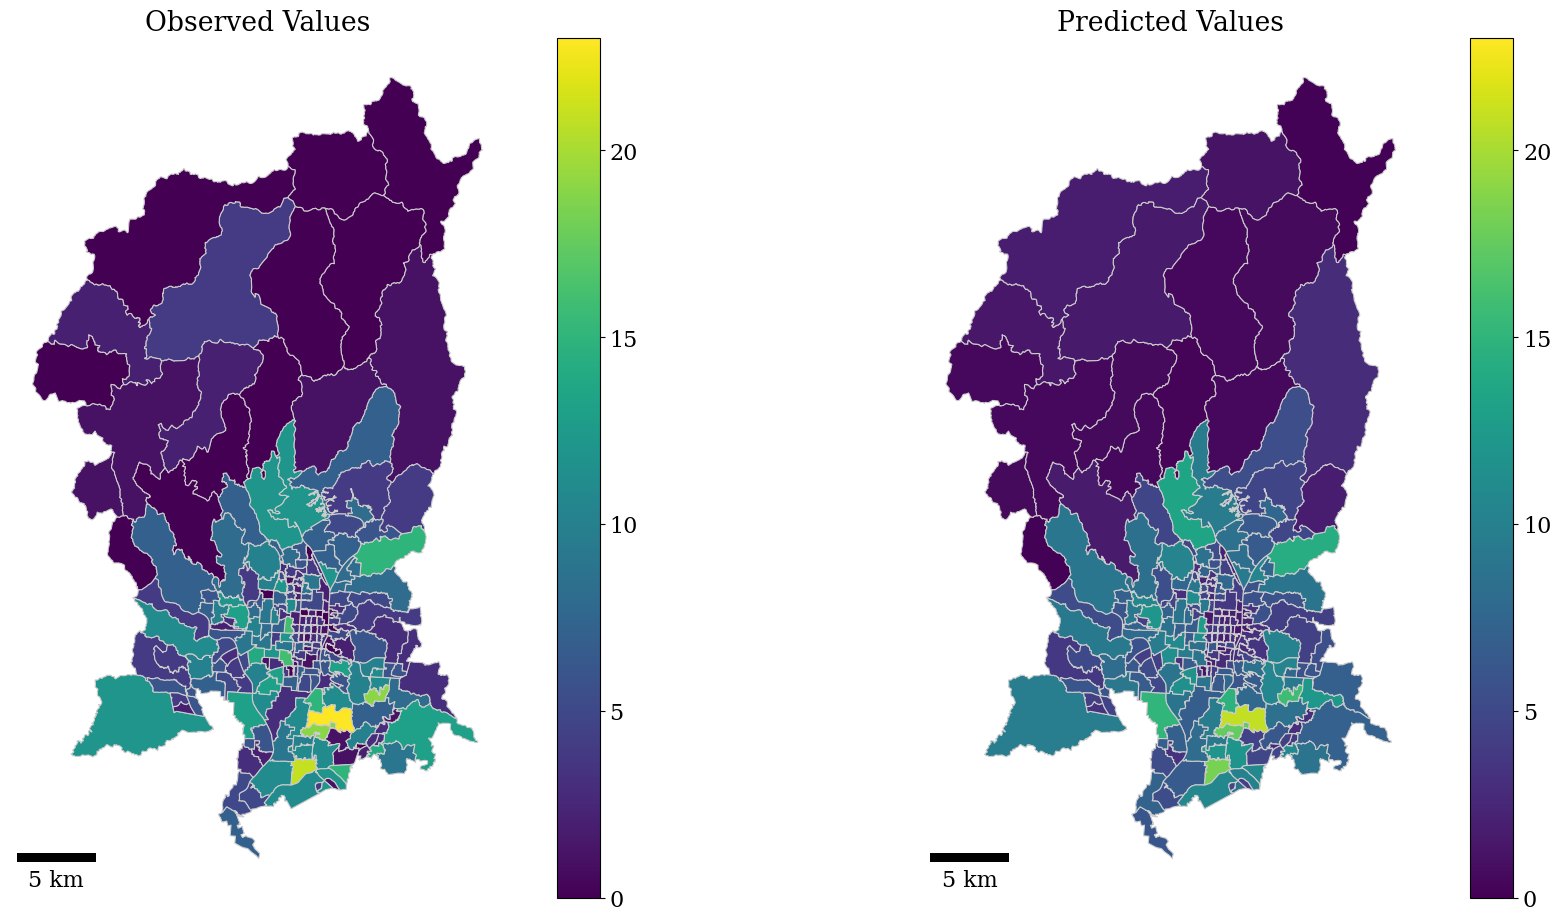

In [ ]:
# Plot observed versus posterior mean predicted counts using a shared map color scale.
plt.rcParams["font.size"] = 16

df_gpkg_proj = df_gpkg.to_crs(epsg=32654)

df_gpkg_proj["observed_y"] = y_obs_p
df_gpkg_proj["predicted_y"] = mu_hat_p

# Calculate global min and max for consistent color scaling
global_min = min(df_gpkg_proj["observed_y"].min(), df_gpkg_proj["predicted_y"].min())
global_max = max(df_gpkg_proj["observed_y"].max(), df_gpkg_proj["predicted_y"].max())

fig, axes = plt.subplots(1, 2, figsize=(20, 10)) # Create 1 row, 2 columns of subplots

# Plot observed values on the first subplot with global color scale
df_gpkg_proj.plot(column="observed_y", cmap="viridis", linewidth=0.8, ax=axes[0], edgecolor="0.8", legend=True, vmin=global_min, vmax=global_max)
axes[0].set_title("Observed Values")
axes[0].set_axis_off()
# Add scale bar to the first subplot, using 'm' as unit for EPSG:32654
scalebar0 = ScaleBar(1, "m", location="lower left", frameon=False, color="black", box_color="white", box_alpha=0.8)
axes[0].add_artist(scalebar0)

# Plot predicted values on the second subplot with global color scale
df_gpkg_proj.plot(column="predicted_y", cmap="viridis", linewidth=0.8, ax=axes[1], edgecolor="0.8", legend=True, vmin=global_min, vmax=global_max)
axes[1].set_title("Predicted Values")
axes[1].set_axis_off()
# Add scale bar to the second subplot, using 'm' as unit for EPSG:32654
scalebar1 = ScaleBar(1, "m", location="lower left", frameon=False, color="black", box_color="white", box_alpha=0.8)
axes[1].add_artist(scalebar1)

#plt.suptitle("Observed vs. Predicted Values") # Add a main title for the entire figure
plt.tight_layout(rect=[0, 0, 1, 0.95]) # Adjust layout to prevent title overlap
plt.savefig("/content/drive/MyDrive/京都市国勢統計区ポリゴンデータ/observed_vs_predicted.jpg", dpi=300)
plt.show()

In [ ]:
# Inspect the input CRS before interpreting mapped coordinates.
# Check the coordinate reference system (CRS) of the GeoDataFrame.
print(df_gpkg.crs)

EPSG:4326


In [ ]:
# Inspect the UTM 54N projected CRS used for mapping.
# Verify the projected CRS (UTM Zone 54N, EPSG:32654).

print(df_gpkg_proj.crs)

EPSG:32654
